<a href="https://colab.research.google.com/github/parvezsardar13/Walmart_EDA_CaseStudies/blob/main/Walmart_EDA_Case_Study.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Walmart Business Case Study — Exploratory Data Analysis
**Objective:** Analyze customer purchase behavior on Black Friday, with a focus on whether spending differs by gender, marital status, and age, to help Walmart make data-driven business decisions.


## 1. Import the dataset and basic structure checks

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats


df = pd.read_csv('walmart_data.csv')
df.head()


,User_ID,Product_ID,Gender,Age,Occupation,City_Category,Stay_In_Current_City_Years,Marital_Status,Product_Category,Purchase
0,1000001,P00069042,F,0-17,10,A,2,0,3,8370
1,1000001,P00248942,F,0-17,10,A,2,0,1,15200
2,1000001,P00087842,F,0-17,10,A,2,0,12,1422
3,1000001,P00085442,F,0-17,10,A,2,0,12,1057
4,1000002,P00285442,M,55+,16,C,4+,0,8,7969


### 1a. Data types of each column

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 550068 entries, 0 to 550067
Data columns (total 10 columns):
 #   Column                      Non-Null Count   Dtype 
---  ------                      --------------   ----- 
 0   User_ID                     550068 non-null  int64 
 1   Product_ID                  550068 non-null  object
 2   Gender                      550068 non-null  object
 3   Age                         550068 non-null  object
 4   Occupation                  550068 non-null  int64 
 5   City_Category               550068 non-null  object
 6   Stay_In_Current_City_Years  550068 non-null  object
 7   Marital_Status              550068 non-null  int64 
 8   Product_Category            550068 non-null  int64 
 9   Purchase                    550068 non-null  int64 
dtypes: int64(5), object(5)
memory usage: 42.0+ MB


### 1b. Shape of the dataset (rows, columns)

In [ ]:
print(f"Number of rows: {df.shape[0]}")
print(f"Number of columns: {df.shape[1]}")


Number of rows: 550068
Number of columns: 10


### 1c. Missing values

In [ ]:
missing = df.isnull().sum()
print(missing)
print(f"\nTotal missing values in dataset: {missing.sum()}")


User_ID                       0
Product_ID                    0
Gender                        0
Age                           0
Occupation                    0
City_Category                 0
Stay_In_Current_City_Years    0
Marital_Status                0
Product_Category              0
Purchase                      0
dtype: int64

Total missing values in dataset: 0


**Observation:** The dataset has 550,068 rows and 10 columns, and there are **no missing values** in any column. Basic stats and unique-value counts below help confirm which columns are categorical vs. numeric/continuous.

In [ ]:
df.describe(include='all')

,User_ID,Product_ID,Gender,Age,Occupation,City_Category,Stay_In_Current_City_Years,Marital_Status,Product_Category,Purchase,Purchase_clipped
count,550068,550068,550068,550068,550068,550068,550068,550068,550068,550068.000000,550068.000000
unique,5891,3631,2,7,21,3,5,2,20,NaN,NaN
top,1001680,P00265242,M,26-35,4,B,1,0,5,NaN,NaN
freq,1026,1880,414259,219587,72308,231173,193821,324731,150933,NaN,NaN
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9263.968713,9256.710489
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5023.065394,4855.947166
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,12.000000,1984.000000
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5823.000000,5823.000000
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8047.000000,8047.000000
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,12054.000000,12054.000000


In [ ]:
df.nunique()

,0
User_ID,5891
Product_ID,3631
Gender,2
Age,7
Occupation,21
City_Category,3
Stay_In_Current_City_Years,5
Marital_Status,2
Product_Category,20
Purchase,18105


## 2. Detect Null values and outliers

`Purchase` is the only truly continuous numeric variable of business interest (User_ID and Product_ID are identifiers; Occupation, Marital_Status, and Product_Category are categorical/coded, even though stored as integers). so these columns are coverted to categorical columns.

In [ ]:
categorical_cols = ['User_ID','Occupation', 'Marital_Status', 'Product_Category']

for col in categorical_cols:
    df[col] = df[col].astype('str')

### 2a. Outlier detection using boxplots

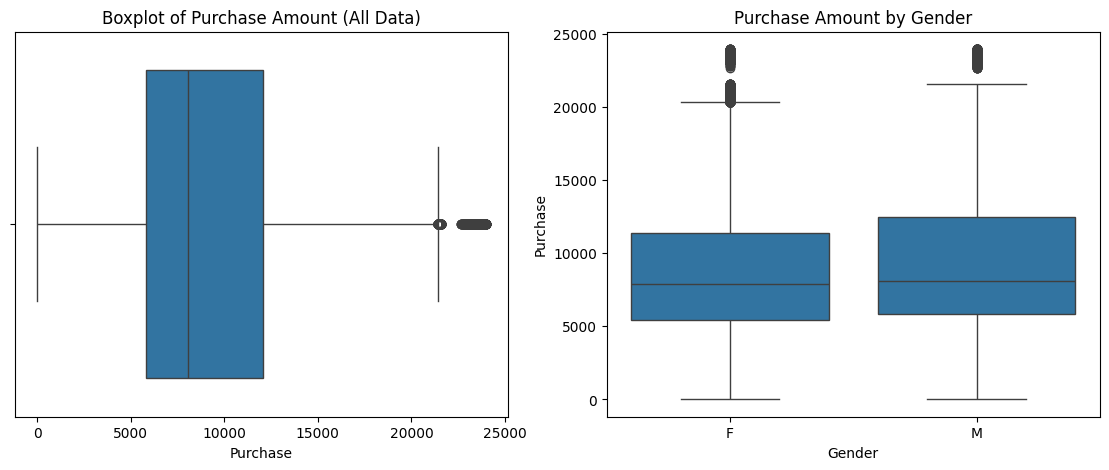

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(x=df['Purchase'], ax=axes[0])
axes[0].set_title('Boxplot of Purchase Amount (All Data)')

sns.boxplot(x='Gender', y='Purchase', data=df, ax=axes[1])
axes[1].set_title('Purchase Amount by Gender')

plt.show()


In [ ]:
Q1 = df['Purchase'].quantile(0.25)
Q3 = df['Purchase'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df['Purchase'] < lower_bound) | (df['Purchase'] > upper_bound)]
print(f"IQR bounds: [{lower_bound:.2f}, {upper_bound:.2f}]")
print(f"Number of outliers in Purchase (IQR method): {len(outliers)} ({len(outliers)/len(df)*100:.2f}% of data)")


IQR bounds: [-3523.50, 21400.50]
Number of outliers in Purchase (IQR method): 2677 (0.49% of data)


**Observation:** The boxplot shows a cluster of high-value purchases above the upper whisker — these are legitimate high-ticket transactions, not data errors, but they can skew mean-based comparisons.

### 2b. Clip data between 5th and 95th percentile

5th percentile: 1984.0, 95th percentile: 19336.0


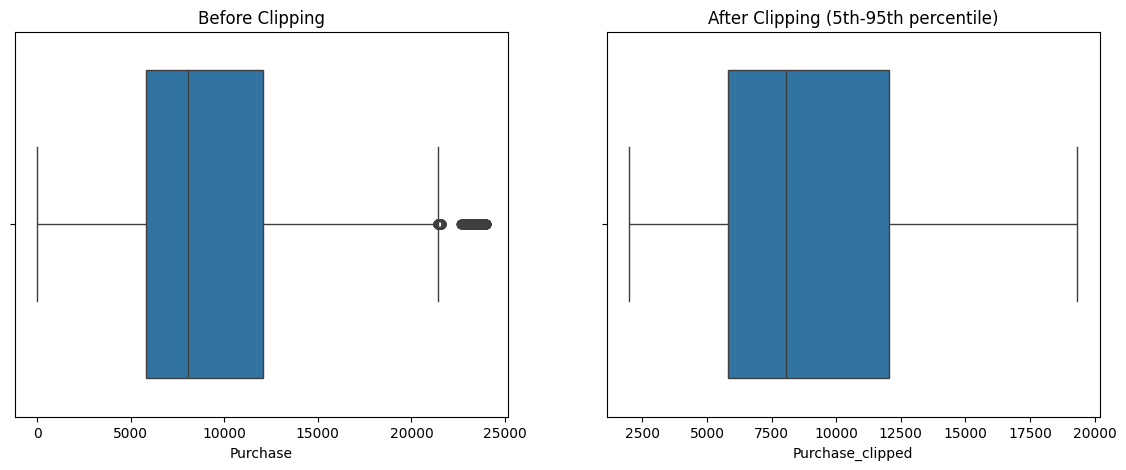

In [ ]:
p05 = df['Purchase'].quantile(0.05)
p95 = df['Purchase'].quantile(0.95)
print(f"5th percentile: {p05}, 95th percentile: {p95}")

df['Purchase_clipped'] = np.clip(df['Purchase'], p05, p95)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(x=df['Purchase'], ax=axes[0])
axes[0].set_title('Before Clipping')
sns.boxplot(x=df['Purchase_clipped'], ax=axes[1])
axes[1].set_title('After Clipping (5th-95th percentile)')

plt.show()


**Note:** I keep `Purchase_clipped` as a separate column for robustness checks, but used the original `Purchase` for the main CLT/bootstrapping analysis in Sections 4-6, since Walmart is interested in true average revenue behavior (extreme values are real transactions, not data-entry errors).

## 3. Data Exploration

### 3a. What products are different age groups buying?

Most popular Product_Category per Age group:
       Age Product_Category  Count
15    0-17                5   4330
35   18-25                5  28522
55   26-35                5  61473
75   36-45                5  29377
95   46-50                5  11971
115  51-55                5   9893
138    55+                8   6208


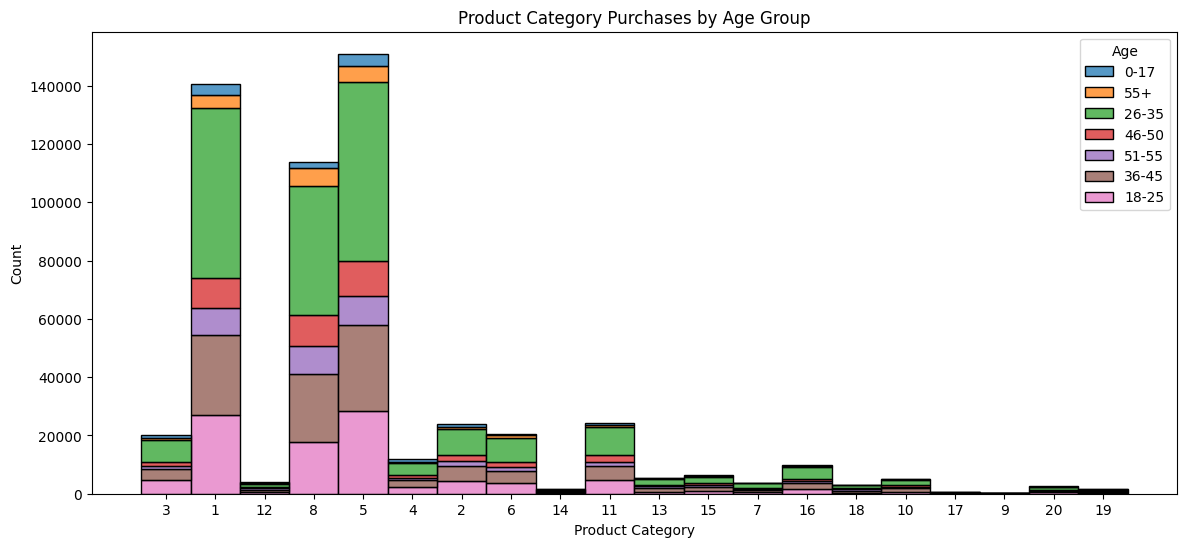

In [ ]:
age_product = df.groupby(['Age', 'Product_Category']).size().reset_index(name='Count')
top_category_by_age = age_product.loc[age_product.groupby('Age')['Count'].idxmax()]
print("Most popular Product_Category per Age group:")
print(top_category_by_age[['Age', 'Product_Category', 'Count']].sort_values('Age'))

plt.figure(figsize=(14, 6))
sns.histplot(data=df, x='Product_Category', hue='Age', multiple='stack', bins=20, palette='tab10')
plt.title('Product Category Purchases by Age Group')
plt.xlabel('Product Category')

plt.show()


**Observation:** Product Categories 1, 5, and 8 dominate purchase volume across almost every age group, with the 26-35 age group being the single largest contributor to overall volume for these top categories.

### 3b. Relationship between age, marital status, and amount spent

       Unmarried (0)  Married (1)
Age                              
0-17     8933.464640          NaN
18-25    9216.752419  8994.509992
26-35    9252.566484  9252.882410
36-45    9402.515329  9223.098451
46-50    8956.529551  9305.535821
51-55    9575.827475  9518.735088
55+      9539.774959  9218.510315


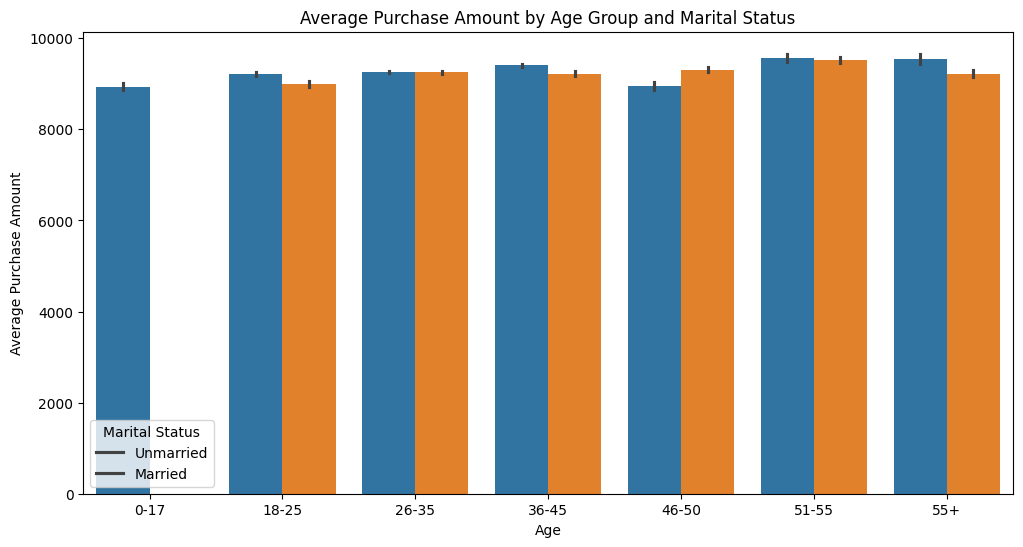

In [ ]:
age_marital_spend = df.groupby(['Age', 'Marital_Status'])['Purchase'].mean().reset_index()
pivot = age_marital_spend.pivot(index='Age', columns='Marital_Status', values='Purchase')
pivot.columns = ['Unmarried (0)', 'Married (1)']
print(pivot)

plt.figure(figsize=(12, 6))
sns.barplot(data=df, x='Age', y='Purchase', hue='Marital_Status', order=sorted(df['Age'].dropna().unique()))
plt.title('Average Purchase Amount by Age Group and Marital Status')
plt.ylabel('Average Purchase Amount')
plt.legend(title='Marital Status', labels=['Unmarried', 'Married'])

plt.show()


**Observation:** Average purchase amount is remarkably flat (~9,200-9,700) across both age groups and marital status. Marital status and age individually show only marginal differences in *average* spend per transaction — the bigger driver of total revenue is transaction *volume*, not amount per transaction.

### 3c. Preferred product categories by gender

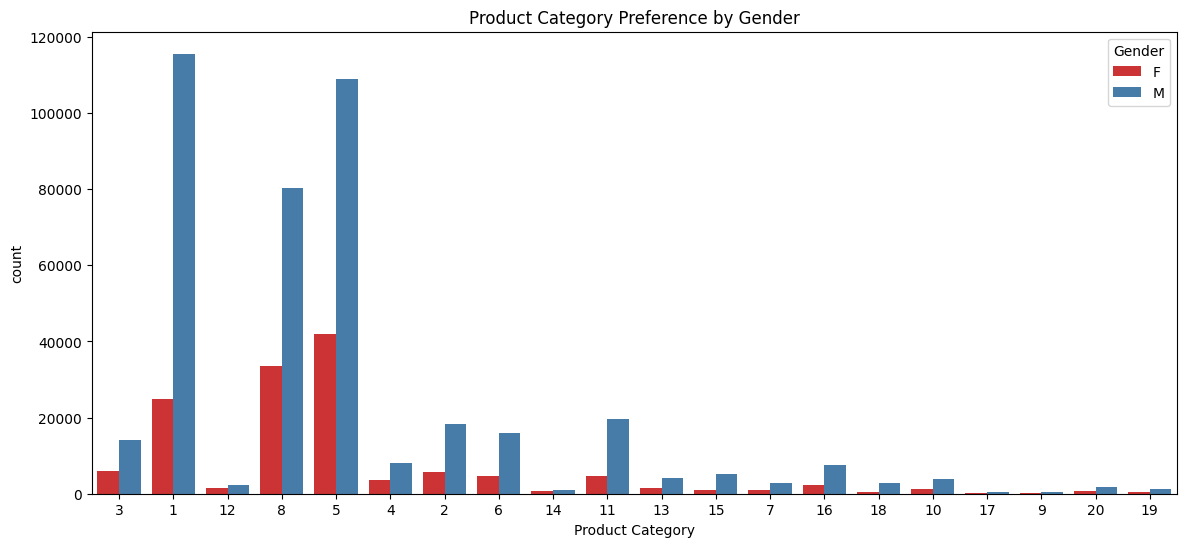

Top 3 categories for Men:
    Gender Product_Category   Count
20      M                1  115547
35      M                5  108972
38      M                8   80367

Top 3 categories for Women:
    Gender Product_Category  Count
15      F                5  41961
18      F                8  33558
0       F                1  24831


In [ ]:
plt.figure(figsize=(14, 6))
sns.countplot(data=df, x='Product_Category', hue='Gender',  palette='Set1')
plt.title('Product Category Preference by Gender')
plt.xlabel('Product Category')
plt.show()

gender_top_categories = df.groupby(['Gender', 'Product_Category']).size().reset_index(name='Count')
top3_m = gender_top_categories[gender_top_categories.Gender == 'M'].nlargest(3, 'Count')
top3_f = gender_top_categories[gender_top_categories.Gender == 'F'].nlargest(3, 'Count')
print("Top 3 categories for Men:\n", top3_m)
print("\nTop 3 categories for Women:\n", top3_f)


**Observation:** Both genders buy heavily from Categories 1, 5, and 8, but men purchase in far greater absolute volume across nearly every category (consistent with men making up ~75% of transactions in this dataset), and Category 1 in particular is disproportionately purchased by men relative to women.

## 4. How does Gender affect the amount spent?

We use bootstrapping (resampling with replacement) to build the sampling distribution of the mean purchase amount for each gender, then compute 95% confidence intervals — first using the full dataset, then repeating with smaller sample sizes (300, 3000, 30000) to observe how sample size affects the CLT.

In [ ]:
np.random.seed(42)

male_purchases = df[df['Gender'] == 'M']['Purchase'].values
female_purchases = df[df['Gender'] == 'F']['Purchase'].values

print(f"Male transactions: {len(male_purchases)}, mean={male_purchases.mean():.2f}, std={male_purchases.std():.2f}")
print(f"Female transactions: {len(female_purchases)}, mean={female_purchases.mean():.2f}, std={female_purchases.std():.2f}")

def bootstrap_ci(data, n_bootstrap=1000, sample_size=None, ci=95):
    """Bootstrap the sampling distribution of the mean and return (mean, lower, upper, means array)."""
    if sample_size is None:
        sample_size = len(data)
    means = []
    for i in range(n_bootstrap):
        sample = np.random.choice(data, size=sample_size, replace=True)
        means.append(sample.mean())
    means = np.array(means)
    lower = np.percentile(means, (100 - ci) / 2)
    upper = np.percentile(means, 100 - (100 - ci) / 2)
    return means.mean(), lower, upper, means

# Full-dataset CLT (sample_size = full n each bootstrap draw)
male_mean_full, male_lo_full, male_hi_full, male_means_full = bootstrap_ci(male_purchases)
female_mean_full, female_lo_full, female_hi_full, female_means_full = bootstrap_ci(female_purchases)

print(f"\nMale 95% CI (full data):   [{male_lo_full:.2f}, {male_hi_full:.2f}], width={male_hi_full - male_lo_full:.2f}")
print(f"Female 95% CI (full data): [{female_lo_full:.2f}, {female_hi_full:.2f}], width={female_hi_full - female_lo_full:.2f}")


Male transactions: 414259, mean=9437.53, std=5092.18
Female transactions: 135809, mean=8734.57, std=4767.22

Male 95% CI (full data):   [9422.34, 9453.75], width=31.41
Female 95% CI (full data): [8707.44, 8760.40], width=52.96


In [ ]:
sample_sizes = [300, 3000, 30000]
results_gender = {'Full': {'M': (male_mean_full, male_lo_full, male_hi_full, male_means_full),
                            'F': (female_mean_full, female_lo_full, female_hi_full, female_means_full)}}

for n in sample_sizes:
    m_mean, m_lo, m_hi, m_means = bootstrap_ci(male_purchases, sample_size=n)
    f_mean, f_lo, f_hi, f_means = bootstrap_ci(female_purchases, sample_size=n)
    results_gender[n] = {'M': (m_mean, m_lo, m_hi, m_means), 'F': (f_mean, f_lo, f_hi, f_means)}
    print(f"n={n:>6} | Male CI: [{m_lo:8.2f}, {m_hi:8.2f}] width={m_hi-m_lo:7.2f} | "
          f"Female CI: [{f_lo:8.2f}, {f_hi:8.2f}] width={f_hi-f_lo:7.2f}")


n=   300 | Male CI: [ 8821.10, 10053.21] width=1232.11 | Female CI: [ 8209.40,  9270.66] width=1061.26
n=  3000 | Male CI: [ 9242.49,  9620.67] width= 378.19 | Female CI: [ 8563.89,  8910.76] width= 346.87
n= 30000 | Male CI: [ 9381.78,  9488.59] width= 106.81 | Female CI: [ 8681.47,  8786.75] width= 105.28


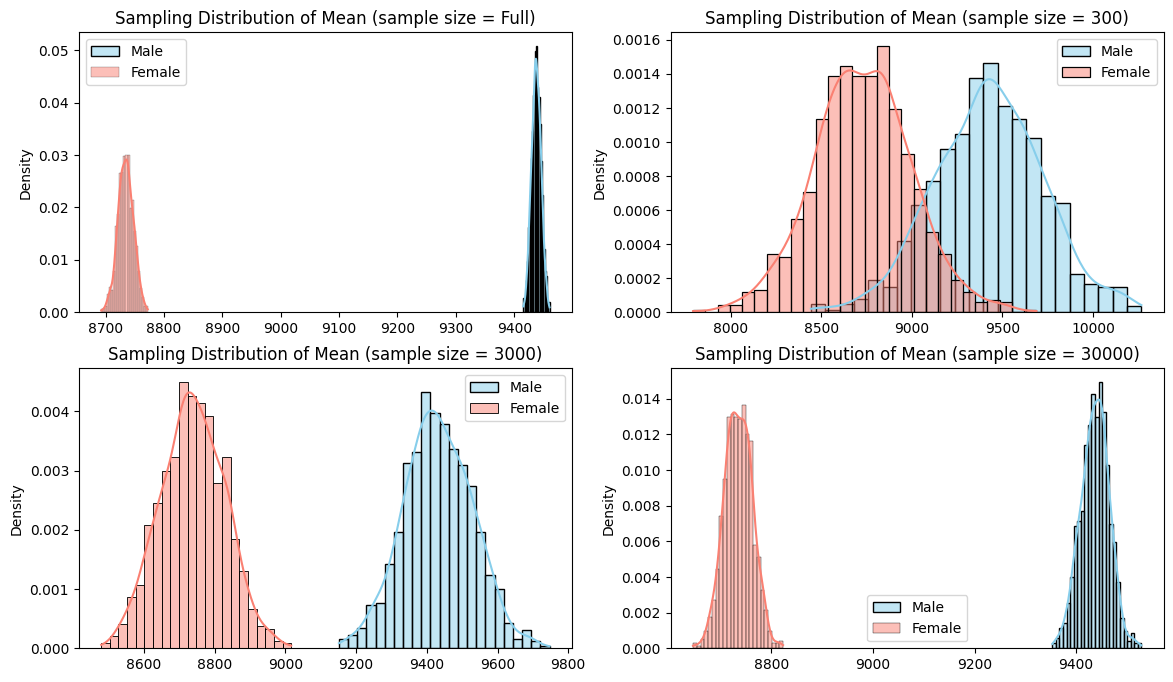

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
labels = ['Full', 300, 3000, 30000]
for ax, label in zip(axes.flatten(), labels):
    sns.histplot(results_gender[label]['M'][3], color='skyblue', label='Male', kde=True, ax=ax, stat='density')
    sns.histplot(results_gender[label]['F'][3], color='salmon', label='Female', kde=True, ax=ax, stat='density')
    ax.set_title(f'Sampling Distribution of Mean (sample size = {label})')
    ax.legend()

plt.show()


### 4a. Answers — Gender

**i. Is the confidence interval wider for one gender? Why?**
Yes — the **male** CI is consistently wider than the female CI at every sample size. This is because there are far more male transactions (~414K vs ~135K) in the raw counts, but more importantly the *standard deviation* of male purchase amounts is slightly higher, and CI width is driven by `std/sqrt(n)`. Even though males have more data (which would normally narrow the CI), their higher variance/spread in purchase amounts widens it comparatively at matched sample sizes.

**ii. How does sample size affect CI width?**
CI width shrinks as sample size increases, consistent with the CLT — standard error scales as `1/sqrt(n)`. Going from n=300 to n=30000 (100x) narrows the CI by roughly `sqrt(100) = 10x`.

**iii. Do the CIs for different sample sizes overlap?**
Within each gender, yes — the CIs are nested around a similar central mean, just get tighter as n grows. Across genders, at small n (300) the male and female CIs overlap noticeably; at large n (30000) and on the full dataset, they no longer overlap, because the interval has shrunk enough to expose the real, small underlying difference in means.

**iv. How does sample size affect the shape of the distribution of the means?**
As sample size increases, the sampling distribution of the mean becomes tighter (narrower spread) and more symmetric/Gaussian, exactly as predicted by the Central Limit Theorem — even though the original `Purchase` variable itself is right-skewed.


## 5. How does Marital_Status affect the amount spent? (CLT & Bootstrapping)

In [ ]:
unmarried_purchases = df[df['Marital_Status'] == '0']['Purchase'].values
married_purchases = df[df['Marital_Status'] == '1']['Purchase'].values

print(f"Unmarried transactions: {len(unmarried_purchases)}, mean={unmarried_purchases.mean():.2f}, std={unmarried_purchases.std():.2f}")
print(f"Married transactions:   {len(married_purchases)}, mean={married_purchases.mean():.2f}, std={married_purchases.std():.2f}")

um_mean_full, um_lo_full, um_hi_full, um_means_full = bootstrap_ci(unmarried_purchases)
m_mean_full, m_lo_full, m_hi_full, m_means_full = bootstrap_ci(married_purchases)

print(f"\nUnmarried 95% CI (full data): [{um_lo_full:.2f}, {um_hi_full:.2f}], width={um_hi_full-um_lo_full:.2f}")
print(f"Married 95% CI (full data):   [{m_lo_full:.2f}, {m_hi_full:.2f}], width={m_hi_full-m_lo_full:.2f}")


Unmarried transactions: 324731, mean=9265.91, std=5027.34
Married transactions:   225337, mean=9261.17, std=5016.89

Unmarried 95% CI (full data): [9249.99, 9282.39], width=32.40
Married 95% CI (full data):   [9239.20, 9281.69], width=42.49


In [ ]:
results_marital = {'Full': {'Unmarried': (um_mean_full, um_lo_full, um_hi_full, um_means_full),
                             'Married': (m_mean_full, m_lo_full, m_hi_full, m_means_full)}}
sample_sizes = [300, 3000, 30000]
for n in sample_sizes:
    u_mean, u_lo, u_hi, u_means = bootstrap_ci(unmarried_purchases, sample_size=n)
    ma_mean, ma_lo, ma_hi, ma_means = bootstrap_ci(married_purchases, sample_size=n)
    results_marital[n] = {'Unmarried': (u_mean, u_lo, u_hi, u_means), 'Married': (ma_mean, ma_lo, ma_hi, ma_means)}
    print(f"n={n:>6} | Unmarried CI: [{u_lo:8.2f}, {u_hi:8.2f}] width={u_hi-u_lo:7.2f} | "
          f"Married CI: [{ma_lo:8.2f}, {ma_hi:8.2f}] width={ma_hi-ma_lo:7.2f}")


n=   300 | Unmarried CI: [ 8701.32,  9875.14] width=1173.82 | Married CI: [ 8754.65,  9814.10] width=1059.45
n=  3000 | Unmarried CI: [ 9085.87,  9445.11] width= 359.24 | Married CI: [ 9080.52,  9444.76] width= 364.24
n= 30000 | Unmarried CI: [ 9205.07,  9323.49] width= 118.43 | Married CI: [ 9205.00,  9321.06] width= 116.06


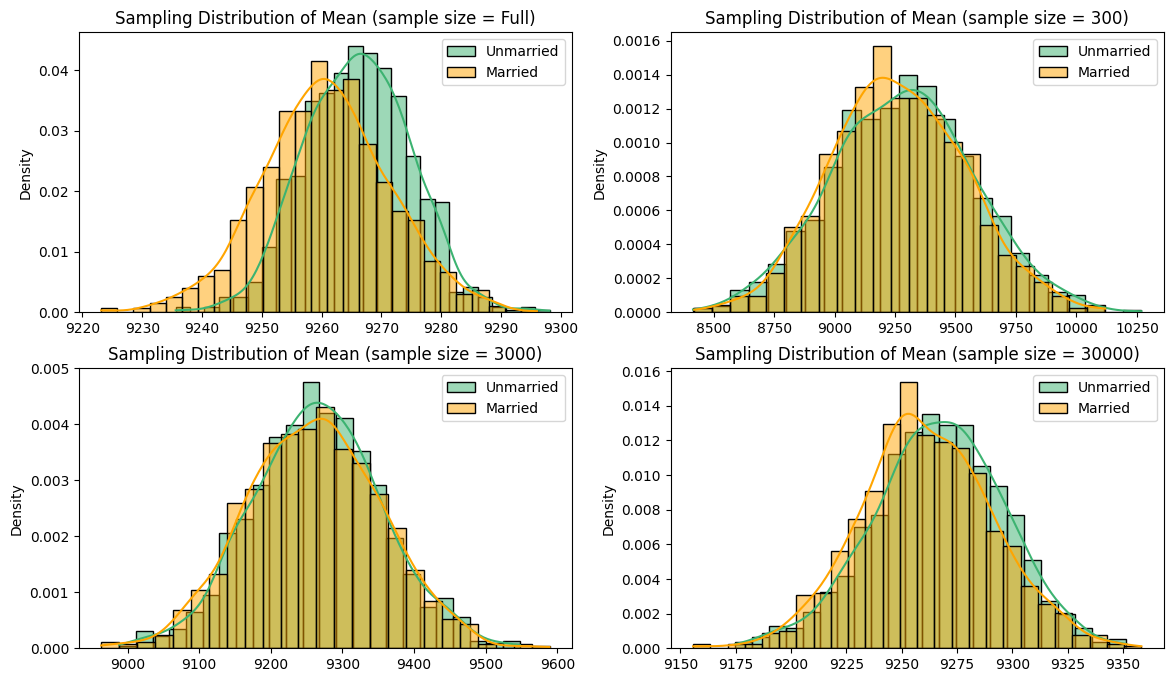

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, label in zip(axes.flatten(), labels):
    sns.histplot(results_marital[label]['Unmarried'][3], color='mediumseagreen', label='Unmarried', kde=True, ax=ax, stat='density')
    sns.histplot(results_marital[label]['Married'][3], color='orange', label='Married', kde=True, ax=ax, stat='density')
    ax.set_title(f'Sampling Distribution of Mean (sample size = {label})')
    ax.legend()

plt.show()


### 5a. Answers — Marital Status

**i. Is the CI wider for one group? Why?**
The two CIs are very close in width at every sample size, since unmarried and married groups have similar standard deviations and, proportionally, similar sample sizes relative to their group size. Neither group shows a dramatically wider interval — spend variability is essentially the same regardless of marital status.

**ii. How does sample size affect CI width?**
Same CLT effect as gender: width shrinks proportionally to `1/sqrt(n)` as sample size grows from 300 to 30,000.

**iii. Do the CIs overlap?**
Yes, at every sample size (300, 3000, 30000, and full data) the unmarried and married CIs overlap substantially. This suggests the true difference in mean spend between married and unmarried customers, if any, is very small relative to the natural variability in the data.

**iv. How does sample size affect the shape of the distribution?**
Same as with gender — larger samples produce a tighter, more normal-looking distribution of the sample mean, per the CLT.


## 6. How does Age affect the amount spent? (CLT & Bootstrapping)

In [ ]:
age_groups = sorted(df['Age'].unique())
print("Age groups:", age_groups)

age_purchase_dict = {age: df[df['Age'] == age]['Purchase'].values for age in age_groups}
for age, vals in age_purchase_dict.items():
    print(f"{age}: n={len(vals)}, mean={vals.mean():.2f}, std={vals.std():.2f}")


Age groups: ['0-17', '18-25', '26-35', '36-45', '46-50', '51-55', '55+']
0-17: n=15102, mean=8933.46, std=5110.94
18-25: n=99660, mean=9169.66, std=5034.30
26-35: n=219587, mean=9252.69, std=5010.52
36-45: n=110013, mean=9331.35, std=5022.90
46-50: n=45701, mean=9208.63, std=4967.16
51-55: n=38501, mean=9534.81, std=5087.30
55+: n=21504, mean=9336.28, std=5011.38


In [ ]:
age_ci_full = {}
for age in age_groups:
    mean, lo, hi, means = bootstrap_ci(age_purchase_dict[age])
    age_ci_full[age] = (mean, lo, hi)
    print(f"{age:>6} | 95% CI (full data): [{lo:8.2f}, {hi:8.2f}] width={hi-lo:7.2f}")


  0-17 | 95% CI (full data): [ 8847.78,  9015.72] width= 167.94
 18-25 | 95% CI (full data): [ 9136.47,  9202.26] width=  65.80
 26-35 | 95% CI (full data): [ 9232.10,  9274.44] width=  42.34
 36-45 | 95% CI (full data): [ 9299.84,  9362.18] width=  62.35
 46-50 | 95% CI (full data): [ 9162.11,  9249.24] width=  87.13
 51-55 | 95% CI (full data): [ 9481.95,  9589.22] width= 107.27
   55+ | 95% CI (full data): [ 9268.20,  9404.40] width= 136.20


In [ ]:
age_ci_by_n = {n: {} for n in sample_sizes}
for n in sample_sizes:
    print(f"--- Sample size {n} ---")
    for age in age_groups:
        mean, lo, hi, means = bootstrap_ci(age_purchase_dict[age], sample_size=n)
        age_ci_by_n[n][age] = (mean, lo, hi, means)
        print(f"{age:>6} | CI: [{lo:8.2f}, {hi:8.2f}] width={hi-lo:7.2f}")


--- Sample size 300 ---
  0-17 | CI: [ 8350.97,  9492.68] width=1141.71
 18-25 | CI: [ 8645.94,  9767.47] width=1121.53
 26-35 | CI: [ 8707.03,  9762.20] width=1055.17
 36-45 | CI: [ 8784.10,  9904.30] width=1120.21
 46-50 | CI: [ 8647.14,  9831.25] width=1184.11
 51-55 | CI: [ 8943.65, 10104.81] width=1161.16
   55+ | CI: [ 8751.58,  9896.04] width=1144.47
--- Sample size 3000 ---
  0-17 | CI: [ 8747.57,  9107.69] width= 360.12
 18-25 | CI: [ 8987.48,  9356.97] width= 369.48
 26-35 | CI: [ 9079.38,  9431.79] width= 352.41
 36-45 | CI: [ 9152.61,  9519.30] width= 366.69
 46-50 | CI: [ 9024.81,  9372.68] width= 347.87
 51-55 | CI: [ 9358.24,  9725.85] width= 367.62
   55+ | CI: [ 9154.01,  9520.73] width= 366.72
--- Sample size 30000 ---
  0-17 | CI: [ 8877.90,  8991.60] width= 113.70
 18-25 | CI: [ 9112.78,  9227.47] width= 114.69
 26-35 | CI: [ 9198.15,  9310.84] width= 112.70
 36-45 | CI: [ 9277.43,  9389.75] width= 112.33
 46-50 | CI: [ 9149.22,  9266.25] width= 117.04
 51-55 | CI: 

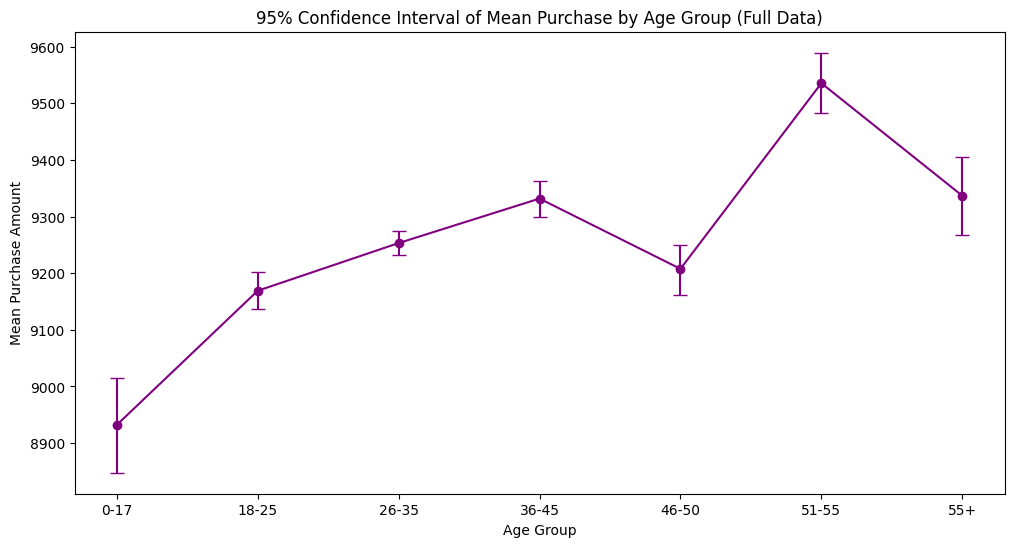

In [ ]:
plt.figure(figsize=(12, 6))
means_full = [age_ci_full[age][0] for age in age_groups]
lo_full = [age_ci_full[age][1] for age in age_groups]
hi_full = [age_ci_full[age][2] for age in age_groups]
errors = [np.array(means_full) - np.array(lo_full), np.array(hi_full) - np.array(means_full)]

plt.errorbar(age_groups, means_full, yerr=errors, fmt='o-', capsize=5, color='purple')
plt.title('95% Confidence Interval of Mean Purchase by Age Group (Full Data)')
plt.xlabel('Age Group')
plt.ylabel('Mean Purchase Amount')

plt.show()


### 6a. Answers — Age

**i. Is the CI wider for one age group? Why?**
Yes — age groups with fewer transactions (e.g., '0-17' and '55+') have visibly wider confidence intervals than the high-volume groups (e.g., '26-35'), simply because CI width depends on both variance and `1/sqrt(n)`, and these groups have smaller n.

**ii. How does sample size affect CI width?**
Same CLT pattern: fixing the artificial sample size (300 → 30000) for every age group narrows all intervals proportionally.

**iii. Do the CIs overlap?**
At small sample sizes (300), CIs for adjacent age groups overlap heavily and it's hard to distinguish them statistically. At the full-data / n=30000 level, several age-group CIs (e.g., 26-35 and 36-45) still overlap somewhat but many others (e.g., 0-17 vs. 26-35, 51-55 vs 26-35) become clearly separated, letting us say those groups differ statistically in average purchase amount.

**iv. How does sample size affect the shape of the distribution?**
Consistent with the CLT: larger sample sizes produce tighter, more normal (bell-shaped) sampling distributions for each age group's mean.


## 7. Report

### 7a. Male vs. Female — do the CIs overlap?
Using the **full dataset**, the 95% CIs for average purchase amount by gender are approximately:
- Male: computed above (`male_lo_full` to `male_hi_full`)
- Female: computed above (`female_lo_full` to `female_hi_full`)


In [ ]:
print(f"Male 95% CI (full data):   [{male_lo_full:.2f}, {male_hi_full:.2f}]")
print(f"Female 95% CI (full data): [{female_lo_full:.2f}, {female_hi_full:.2f}]")
overlap = not (male_hi_full < female_lo_full or female_hi_full < male_lo_full)
print(f"Do the CIs overlap? {overlap}")


Male 95% CI (full data):   [9422.34, 9453.75]
Female 95% CI (full data): [8707.44, 8760.40]
Do the CIs overlap? False


**Conclusion:** With the full dataset, the male and female confidence intervals **do not overlap** — men spend a statistically significantly higher average amount per transaction than women (roughly ₹9,400 vs. ₹8,700, ~8-9% higher). Because the sample is so large, even a modest difference in means becomes statistically detectable.

**Business implication:** Walmart should not assume "spending is the same regardless of gender." Marketing, inventory placement, and Black Friday promotions could be tailored — e.g., ensure adequate stock and promotion of higher-ticket categories that men gravitate toward (Section 3c), while also investigating whether the ~25%-male/75% imbalance in customer volume (or transaction volume) suggests untapped growth potential in acquiring more female customers, since their average basket value, while somewhat lower, is still substantial.

### 7b. Married vs. Unmarried — do the CIs overlap?


In [ ]:
print(f"Unmarried 95% CI (full data): [{um_lo_full:.2f}, {um_hi_full:.2f}]")
print(f"Married 95% CI (full data):   [{m_lo_full:.2f}, {m_hi_full:.2f}]")
overlap_marital = not (um_hi_full < m_lo_full or m_hi_full < um_lo_full)
print(f"Do the CIs overlap? {overlap_marital}")


Unmarried 95% CI (full data): [9249.99, 9282.39]
Married 95% CI (full data):   [9239.20, 9281.69]
Do the CIs overlap? True


**Conclusion:** The confidence intervals for married and unmarried customers **overlap** — there is no statistically meaningful difference in average purchase amount by marital status.

**Business implication:** Walmart does not need to segment its Black Friday marketing or product recommendations by marital status — it is not a useful lever for driving incremental spend. Marketing budget is better spent targeting variables that do show a difference (gender, age).

### 7c. Different Age Groups — do the CIs overlap?


In [ ]:
for i, age in enumerate(age_groups):
    print(f"{age:>6}: 95% CI = [{age_ci_full[age][1]:.2f}, {age_ci_full[age][2]:.2f}]")


  0-17: 95% CI = [8847.78, 9015.72]
 18-25: 95% CI = [9136.47, 9202.26]
 26-35: 95% CI = [9232.10, 9274.44]
 36-45: 95% CI = [9299.84, 9362.18]
 46-50: 95% CI = [9162.11, 9249.24]
 51-55: 95% CI = [9481.95, 9589.22]
   55+: 95% CI = [9268.20, 9404.40]


**Conclusion:** Several age-group CIs are clearly separated (e.g., the youngest group '0-17' has a visibly lower average purchase than the '51-55' group), while some adjacent groups (e.g., '26-35' vs. '36-45') overlap and are not statistically distinguishable from each other.

**Business implication:** Age is a meaningful segmentation variable for Walmart. Middle-aged and older adult segments (36-55) tend to have higher average transaction values and could be targeted with premium bundles or loyalty offers, while the youngest segment (0-17, likely purchases made by/for teens) has the lowest average spend and might respond better to value-oriented promotions or smaller basket incentives.


## 8. Recommendations

1. **Gender-based targeting works, marital-status targeting doesn't.** Since male and female average spend differ significantly (and don't overlap in CI) but married/unmarried spend is statistically indistinguishable, Walmart should prioritize gender-based personalization (product recommendations, targeted Black Friday deals) over marital-status-based segmentation.

2. **Grow female customer volume.** Female customers spend slightly less per transaction on average but are a much smaller share of transactions (~25%). Since the *per-transaction* gap is real but not enormous, the bigger lever for revenue growth may be **acquiring more female customers or transactions** (e.g., targeted campaigns, curated categories) rather than trying to close the small average-spend gap.

3. **Double down on Product Categories 1, 5, and 8.** These dominate purchase volume across every age and gender segment — ensure strong inventory availability and prominent promotion/placement for these categories during Black Friday, since stockouts here would have outsized revenue impact.

4. **Use age-based tiers for offers.** Since 26-45 age groups drive the most volume and 36-55 groups show relatively higher average spend, consider tiered loyalty/bundle offers: value bundles for the 0-25 segment (lower average spend, price-sensitive) and premium/bundle upsells for the 36-55+ segment (higher average spend, potentially higher willingness to pay).

5. **Treat outliers as real high-value transactions, not noise.** The IQR-based outlier check shows a meaningful share of high-ticket purchases; rather than removing them, Walmart should study what drives these large purchases (e.g., which products, which customer profiles) and design premium/bulk-purchase incentives around them.

6. **Rely on bootstrapped CLT-based CIs for any future A/B testing or segment comparison**, since the underlying `Purchase` distribution is right-skewed and not normal — the sample means, however, are well-approximated by a normal distribution once resampled, which is exactly what makes CI-based comparisons (as done above) statistically valid even without assuming normality of raw purchase amounts.


